# Analisis Segmentasi Usaha Jasa di Surabaya–Sidoarjo

Notebook ini membersihkan CSV mentah, mengaudit baris bergeser, membangun segmentasi K-Means berbasis rating dan popularitas ulasan, mengevaluasi k=2–6, serta menyimpan tabel hasil. Jalankan berurutan dari atas ke bawah.

> Catatan: CSV mentah tampak memiliki koma tidak ter-escape sehingga sejumlah baris bergeser kolom. Baris dipakai hanya jika rating 0–5, ulasan non-negatif, koordinat masuk akal untuk Jawa Timur, serta sumber/kategori/nama mengidentifikasi usaha jasa laundry, kebersihan, atau perawatan sepatu.


In [1]:
# Jika belum terpasang, aktifkan baris berikut:
# %pip install pandas numpy scikit-learn matplotlib

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

DATA_PATH = Path("data_raw_umkm")  # sesuaikan jika CSV berada di folder lain
OUT_DIR = Path("hasil_analisis")
OUT_DIR.mkdir(exist_ok=True)
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=True)
print("Dimensi data mentah:", df.shape)
display(df.head())


Dimensi data mentah: (988, 25)


,nama_usaha,kategori,alamat,kota,provinsi,kode_pos,jam_operasional,telepon,website,email,...,longitude,link_google_maps,link_ulasan,sumber_file,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24
0,FRANK CLEAN Metropolis,Jasa Semir Sepatu,"Jl. Raya Tenggilis No.127, Tenggilis Mejoyo, K...",Surabaya,Jawa Timur,60294,Senin: 14.00–21.00 | Selasa: Tutup | Rabu: 14....,0813-3121-6336,NaN,NaN,...,112.758.676,https://www.google.com/maps/place/FRANK+CLEAN+...,NaN,Scraping_Jasa,NaN,NaN,NaN,NaN,NaN,NaN
1,Foam Shoes Laundry,cuci sepatu murah sidoarjo,Toko Reparasi Sepatu Boot,"Merak 1 C No.2, Wedoro, Kec. Waru, Kabupaten S...",Kabupaten Sidoarjo,Jawa Timur,61256,Senin: 09.00–20.00 | Selasa: 09.00–20.00 | Rab...,0859-3374-9821,NaN,...,-7.347.365,112.752.536,https://www.google.com/maps/place/Foam+Shoes+L...,NaN,Scraping_Jasa,NaN,NaN,NaN,NaN,NaN
2,CUCI SEPATU SIWALANKERTO (CLEDS),Binatu,"Jl. Siwalankerto Timur No.176, RT.02/RW.05, Si...",Surabaya,Jawa Timur,60236,Senin: 10.00–21.00 | Selasa: 10.00–21.00 | Rab...,0813-2641-5371,NaN,NaN,...,112.738.233,https://www.google.com/maps/place/CUCI+SEPATU+...,NaN,Scraping_Jasa,NaN,NaN,NaN,NaN,NaN,NaN
3,LAUNDRY SEPATU DAN REPARASI SIWALANKERTO ( ROC...,Toko Reparasi Sepatu,"Jl. Siwalankerto No.147, Siwalankerto, Kec. Wo...",Surabaya,Jawa Timur,60236,Senin: 08.00–21.00 | Selasa: 08.00–21.00 | Rab...,0858-5566-3956,https://www.instagram.com/rockshoes.id?igsh=eT...,NaN,...,112.737.782,https://www.google.com/maps/place/LAUNDRY+SEPA...,NaN,Scraping_Jasa,NaN,NaN,NaN,NaN,NaN,NaN
4,ARLIAN SHOES CARE,Layanan Binatu,"Jl. Belahan Wedoro, Belahan, Wedoro, Kec. Waru...",Kabupaten Sidoarjo,Jawa Timur,61256,Senin: 09.00–20.00 | Selasa: 09.00–20.00 | Rab...,0899-8941-403,https://instagram.com/arlian_shoes_care?igshid...,NaN,...,112.750.254,https://www.google.com/maps/place/ARLIAN+SHOES...,NaN,Scraping_Jasa,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
def to_number(value):
    if pd.isna(value): return np.nan
    s = str(value).strip().replace(",", ".")
    # memperbaiki format koordinat seperti -7.320.130 -> -7.320130
    if s.count(".") > 1:
        parts = s.split(".")
        s = parts[0] + "." + "".join(parts[1:])
    try: return float(s)
    except (TypeError, ValueError): return np.nan

for col in ["rating", "jumlah_ulasan", "latitude", "longitude"]:
    df[col + "_num"] = df[col].map(to_number)

service_pattern = r"laundry|binatu|sepatu|clean|kebersihan|semir"
service_mask = (df["kategori"].fillna("").str.contains(service_pattern, case=False, regex=True) |
                 df["nama_usaha"].fillna("").str.contains(service_pattern, case=False, regex=True) |
                 df["sumber_file"].eq("Scraping_Jasa"))
valid_mask = (df["nama_usaha"].notna() & df["kategori"].notna() &
              df["rating_num"].between(0, 5) & df["jumlah_ulasan_num"].ge(0) &
              df["latitude_num"].between(-8, -6) & df["longitude_num"].between(110, 116))

print({"baris_mentah": len(df), "kandidat_jasa": int(service_mask.sum()),
       "kandidat_valid": int((service_mask & valid_mask).sum()),
       "kandidat_gagal_validasi": int((service_mask & ~valid_mask).sum())})


{'baris_mentah': 988, 'kandidat_jasa': 351, 'kandidat_valid': 277, 'kandidat_gagal_validasi': 74}


In [3]:
clean = df.loc[service_mask & valid_mask].copy()
clean["kota_norm"] = clean["kota"].fillna("").str.lower().map(
    lambda s: "Sidoarjo" if "sidoarjo" in s else ("Surabaya" if "surabaya" in s else "Tidak diketahui"))
addr = clean["alamat"].fillna("").str.lower()
clean.loc[(clean.kota_norm == "Tidak diketahui") & addr.str.contains("sidoarjo|waru|wedoro|tropodo|sedati"), "kota_norm"] = "Sidoarjo"
clean.loc[(clean.kota_norm == "Tidak diketahui") & addr.str.contains("surabaya"), "kota_norm"] = "Surabaya"
clean["name_norm"] = clean["nama_usaha"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
clean = clean.sort_values("jumlah_ulasan_num", ascending=False).drop_duplicates(
    subset=["name_norm", "latitude_num", "longitude_num"], keep="first").copy()
print("Baris setelah filter dan deduplikasi:", len(clean))
print("Listing rating 0 & ulasan 0 (dipisah):", int(((clean.rating_num == 0) & (clean.jumlah_ulasan_num == 0)).sum()))
print("Listing tanpa rating/ulasan:", int(((clean.rating_num == 0) & (clean.jumlah_ulasan_num == 0)).sum()))
print("Kota:"); display(clean.kota_norm.value_counts(dropna=False).to_frame("jumlah"))
print("Kategori teratas:"); display(clean.kategori.value_counts().head(15).to_frame("jumlah"))


Baris setelah filter dan deduplikasi: 277
Listing rating 0 & ulasan 0 (dipisah): 10
Listing tanpa rating/ulasan: 10
Kota:


,jumlah
kota_norm,
Surabaya,218
Sidoarjo,59


Kategori teratas:


,jumlah
kategori,
Layanan Binatu,118
Binatu,87
Binatu Cucian Kering,24
Toko Reparasi Sepatu,22
Jasa Semir Sepatu,9
Layanan Kebersihan,7
Pemasok peralatan binatu yang dioperasikan dengan koin,4
Toko Sepatu,3
Jasa Pembersihan,2


In [4]:
# Rating merepresentasikan kepuasan agregat; log(1 + jumlah ulasan) meredam kemencengan popularitas.
# Lokasi tidak dimasukkan ke jarak K-Means agar segmentasi perilaku tidak didominasi koordinat.
no_review = clean["rating_num"].eq(0) & clean["jumlah_ulasan_num"].eq(0)
cluster_data = clean.loc[~no_review].copy()
X = cluster_data[["rating_num"]].copy()
X["log_jumlah_ulasan"] = np.log1p(cluster_data["jumlah_ulasan_num"])
scaler = StandardScaler()
Z = scaler.fit_transform(X)

metric_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(Z)
    metric_rows.append({"k": k, "inertia": km.inertia_,
        "silhouette": silhouette_score(Z, labels),
        "davies_bouldin": davies_bouldin_score(Z, labels),
        "calinski_harabasz": calinski_harabasz_score(Z, labels)})
metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,339.2257,0.4162,1.0163,152.1559
1,3,178.3274,0.4969,0.6929,263.2730
2,4,131.1910,0.5060,0.7412,269.1719
3,5,100.1816,0.4302,0.7438,283.6361
4,6,78.5292,0.4438,0.6469,302.7608


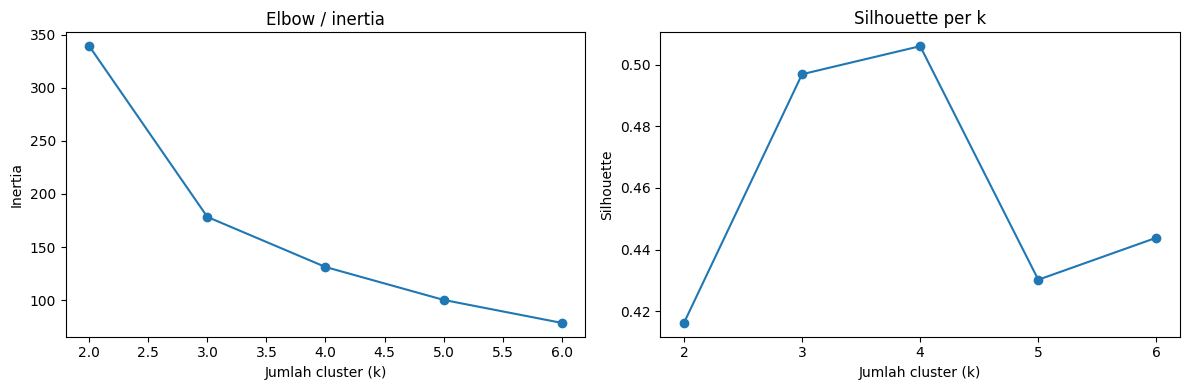

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(metrics.k, metrics.inertia, marker="o"); ax[0].set(title="Elbow / inertia", xlabel="Jumlah cluster (k)", ylabel="Inertia")
ax[1].plot(metrics.k, metrics.silhouette, marker="o", label="Silhouette")
ax[1].set(title="Silhouette per k", xlabel="Jumlah cluster (k)", ylabel="Silhouette", xticks=metrics.k)
plt.tight_layout(); plt.show()


In [6]:
# Aturan utama: pilih silhouette tertinggi; DBI dipakai sebagai pemeriksaan pendamping.
best_k = int(metrics.sort_values(["silhouette", "davies_bouldin"], ascending=[False, True]).iloc[0].k)
final_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
cluster_data["cluster"] = final_model.fit_predict(Z)
print("k terpilih:", best_k)
profile = cluster_data.groupby("cluster").agg(
    jumlah_usaha=("nama_usaha", "size"),
    rating_rata2=("rating_num", "mean"),
    rating_median=("rating_num", "median"),
    ulasan_median=("jumlah_ulasan_num", "median"),
    ulasan_rata2=("jumlah_ulasan_num", "mean"),
    ulasan_total=("jumlah_ulasan_num", "sum"),
    porsi_surabaya=("kota_norm", lambda s: (s == "Surabaya").mean()),
    porsi_sidoarjo=("kota_norm", lambda s: (s == "Sidoarjo").mean())
).reset_index()
display(profile.round(3))


k terpilih: 4


,cluster,jumlah_usaha,rating_rata2,rating_median,ulasan_median,ulasan_rata2,ulasan_total,porsi_surabaya,porsi_sidoarjo
0,0,97,4.956,5.0,5.0,7.485,726.0,0.773,0.227
1,1,120,4.837,4.9,90.5,132.558,15907.0,0.817,0.183
2,2,40,4.210,4.3,15.0,25.125,1005.0,0.725,0.275
3,3,10,2.990,3.2,13.0,18.400,184.0,0.700,0.300


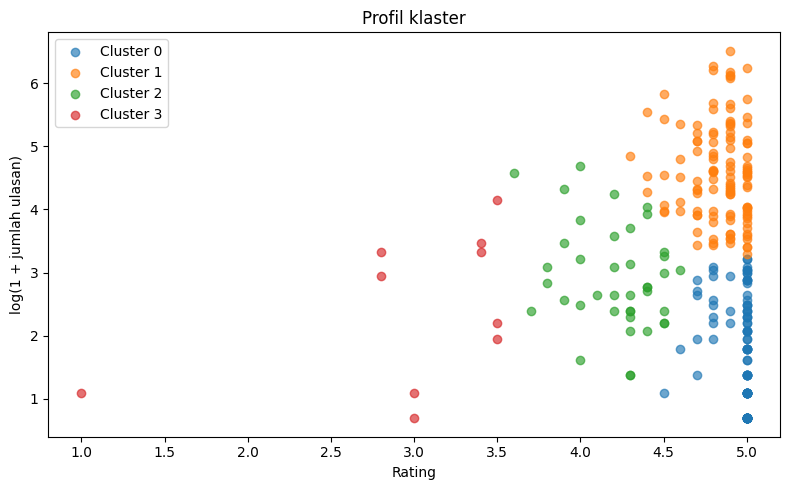

Hasil tersimpan di /content/hasil_analisis


In [7]:
# Plot profil hasil pada skala asli
fig, ax = plt.subplots(figsize=(8, 5))
for cl, g in cluster_data.groupby("cluster"):
    ax.scatter(g["rating_num"], np.log1p(g["jumlah_ulasan_num"]), alpha=.65, label=f"Cluster {cl}")
ax.set(xlabel="Rating", ylabel="log(1 + jumlah ulasan)", title="Profil klaster")
ax.legend(); plt.tight_layout(); plt.show()

metrics.to_csv(OUT_DIR / "metrik_pemilihan_k.csv", index=False)
profile.to_csv(OUT_DIR / "profil_cluster.csv", index=False)
cluster_data.to_csv(OUT_DIR / "data_bersih_dengan_cluster.csv", index=False)
clean.loc[no_review].to_csv(OUT_DIR / "listing_tanpa_ulasan.csv", index=False)
print("Hasil tersimpan di", OUT_DIR.resolve())


## Cara membaca hasil

- Silhouette mendekati 1 berarti pemisahan lebih baik; mendekati 0 berarti klaster bertumpang tindih; nilai negatif menandai banyak objek lebih dekat ke klaster lain.
- DBI lebih kecil biasanya lebih baik; Calinski–Harabasz lebih besar biasanya lebih baik. Jangan memilih k dari satu metrik saja.
- Karena hanya rating dan log jumlah ulasan yang tersedia dan dipakai, label klaster adalah segmen reputasi/popularitas, bukan ukuran UMKM, omzet, kualitas kausal, atau kelayakan bantuan.
- Listing dengan rating 0 dan jumlah ulasan 0 dipisahkan sebagai belum memiliki umpan balik dan tidak ikut membentuk klaster utama.
